# 자료의 분포와 통계 요약

작은 예제로 원리 확인 → 코드 실행 → 한 조건 변경 → 결과 해석

위에서 아래로 실행. 일반 CPU로 진행 가능. 날짜·평가 운영은 학기 운영안내에서 확인

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
np.set_printoptions(precision=5, suppress=True)

## 자료의 한 행과 한 열

포유류 수면 자료 `msleep.csv`에서 한 행과 한 열이 의미하는 바를 설명하시오. 수면시간의 단위를 확인하시오.

In [2]:
from pathlib import Path
base = Path('../data')
raw_url = 'https://raw.githubusercontent.com/steelpl/lecture/main/CE387-big-data-analysis/data/'
def read_data(name):
    path = base / name
    return pd.read_csv(path if path.exists() else raw_url + name)

In [3]:
sleep = read_data('msleep.csv')
display(sleep[['name','vore','sleep_total','bodywt']].head())
print('행·열:', sleep.shape)
print('결측 수:', sleep['sleep_total'].isna().sum())
display(sleep['sleep_total'].describe())

,name,vore,sleep_total,bodywt
0,Cheetah,carni,12.1,50.000
1,Owl monkey,omni,17.0,0.480
2,Mountain beaver,herbi,14.4,1.350
3,Greater short-tailed shrew,omni,14.9,0.019
4,Cow,herbi,4.0,600.000


행·열: (83, 11)
결측 수: 0


count    83.000000
mean     10.433735
std       4.450357
min       1.900000
25%       7.850000
50%      10.100000
75%      13.750000
max      19.900000
Name: sleep_total, dtype: float64

수면시간: 하루 중 시간, 체중: kg. 표본의 평균·중앙값·범위를 구분. 종별 관측을 개별 동물의 반복 측정으로 해석하지 않음.

## 분포 확인

수면시간과 체중을 각각 그리시오. 평균 하나로 설명하기 어려운 부분을 찾으시오.

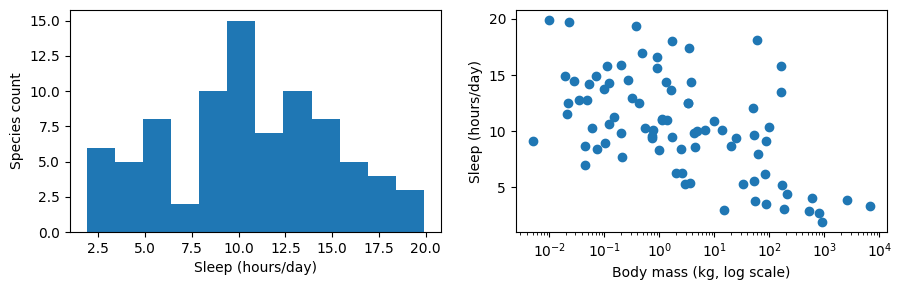

In [4]:
fig, ax = plt.subplots(1,2,figsize=(9,3))
ax[0].hist(sleep['sleep_total'].dropna(), bins=12)
ax[0].set(xlabel='Sleep (hours/day)', ylabel='Species count')
ax[1].scatter(sleep['bodywt'], sleep['sleep_total'])
ax[1].set(xscale='log', xlabel='Body mass (kg, log scale)', ylabel='Sleep (hours/day)')
plt.tight_layout(); plt.show()

## 관측 연도와 인과관계

행복도 자료의 관측 연도는 자료의 일부. `2019.csv`의 국가별 점수와 1인당 GDP 관련 변수의 상관계수를 구하시오. 인과관계라고 말할 수 있는지 설명하시오.

In [5]:
happy = read_data('2019.csv')
columns = ['Score','GDP per capita']
print(happy[columns].corr())
print('각 열의 결측 수:'); print(happy[columns].isna().sum())

                   Score  GDP per capita
Score           1.000000        0.793883
GDP per capita  0.793883        1.000000
각 열의 결측 수:
Score             0
GDP per capita    0
dtype: int64


분석 단위·자료 수집 맥락·누락·다른 영향 요인 검토. 상관관계만으로 원인·결과 결정 불가

## 이산·연속 분포

동전 10회에서 앞면 7회, 평균 발생 횟수 8인 포아송 변수에서 5회 이하, 평균 160·표준편차 5인 가상 키 분포에서 154 미만일 확률을 각각 구하시오. 확률질량과 확률밀도의 차이를 설명하시오.

In [6]:
from scipy import stats
print('Binomial P(X=7):',stats.binom.pmf(7,10,.5))
print('Poisson P(X<=5):',stats.poisson.cdf(5,8))
print('Normal P(X<154):',stats.norm.cdf(154,loc=160,scale=5))
print('Exponential P(T>4), rate=.5:',stats.expon.sf(4,scale=1/.5))

Binomial P(X=7): 0.11718749999999999
Poisson P(X<=5): 0.19123606207962532
Normal P(X<154): 0.11506967022170822
Exponential P(T>4), rate=.5: 0.1353352832366127


## 표본평균의 분포

주사위 5회·100회 결과의 평균을 각각 1,000개 생성하시오. 개별 값의 분포와 표본평균의 분포를 구분하고, 표본 크기에 따른 퍼짐을 설명하시오.

5 평균: 3.4874 표준편차: 0.7620506807293069 이론 표준편차: 0.7637626158259733
100 평균: 3.50079 표준편차: 0.17017072574329584 이론 표준편차: 0.1707825127659933


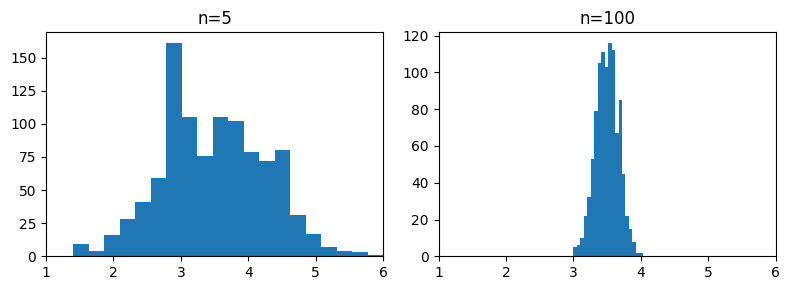

In [7]:
rng=np.random.default_rng(42)
fig,ax=plt.subplots(1,2,figsize=(8,3))
for a,size in zip(ax,[5,100]):
    means=rng.integers(1,7,size=(1000,size)).mean(axis=1)
    a.hist(means,bins=20);a.set(xlim=(1,6),title=f'n={size}')
    print(size,'평균:',means.mean(),'표준편차:',means.std(),
          '이론 표준편차:',np.sqrt((35/12)/size))
plt.tight_layout();plt.show()

## 일원 분산분석

세 집단의 Days 자료가 각각 `[5.3,6.0,6.7]`, `[5.5,6.2,6.4,5.7]`, `[7.5,7.2,7.9]`이다. 집단 평균이 같다는 귀무가설을 F 통계량과 p값으로 검토하시오.

독립 관측·집단 내 정규성·등분산 가정 필요. 작은 예제만으로 가정을 확인했다고 판단하지 않음. 기각 시 어느 집단끼리 다른지는 별도 비교 필요

In [8]:
groups=[np.array([5.3,6.0,6.7]),np.array([5.5,6.2,6.4,5.7]),np.array([7.5,7.2,7.9])]
print(stats.f_oneway(*groups))
all_values=np.concatenate(groups);grand=all_values.mean()
ss_between=sum(len(g)*(g.mean()-grand)**2 for g in groups)
ss_within=sum(np.sum((g-g.mean())**2) for g in groups)
F=(ss_between/(len(groups)-1))/(ss_within/(len(all_values)-len(groups)))
print('손계산 F:',F)
assert np.isclose(F,stats.f_oneway(*groups).statistic)

F_onewayResult(statistic=np.float64(10.2157495256167), pvalue=np.float64(0.008394015096171622))
손계산 F: 10.2157495256167
